# TP3 Dataset « big » : images de vêtements (Outfit Items) - OZEL IBRAHIM

Objectif : reconnaître automatiquement le type d'un article de mode à partir de sa photo.

Chaîne suivie : **EDA → prétraitement → transformation → ML → évaluation**.

Données : [Outfit Items (Kaggle)](https://www.kaggle.com/datasets/kritanjalijain/outfititems), environ **49 000 images PNG pour ~7 Go**, réparties en 5 catégories et 13 sous-catégories :

| Catégorie | Sous-catégories |
|---|---|
| Upperwear | shirt, t-shirt, jacket |
| Bottomwear | pants, skirt, shorts |
| Footwear | shoes, sneakers, heels, flats |
| One-piece | dress |
| Accessories | hats, bags |

C'est un problème de **classification multi-classe** : la cible est la sous-catégorie (13 classes).

**Pourquoi c'est du « big data »** : 7 Go d'images ne tiennent pas confortablement en mémoire une fois décodées (49 000 × 224 × 224 × 3 octets ≈ 7,4 Go en uint8, 4 fois plus en float32). On ne charge donc **jamais** tout le dataset en mémoire :
- **EDA et prétraitement avec Spark** : l'inventaire, les statistiques et la vérification des 50 000 fichiers sont répartis sur tous les cœurs ; seuls des résultats agrégés ou des métadonnées (chemin, classe) reviennent au driver ;
- **transformation et ML avec TensorFlow** : les images sont lues, décodées et transformées **en flux, par lots**, avec `tf.data`.

## Contribution

**Le notebook s'exécute-t-il de bout en bout ?** Oui : toutes les cellules s'exécutent sans erreur (EDA et prétraitement avec Spark, entraînement de MobileNetV2 sur CPU, ce qui est long).

**Problèmes rencontrés**
- Le dataset (~7 Go) ne tient pas en mémoire une fois décodé (16 Go de RAM) : tout est lu en flux.
- PySpark a besoin de Java 17, alors que le Java par défaut de la machine est trop ancien : le notebook installe un JDK 17 dans `~/.jdk`.
- L'entraînement est long sur CPU, il faut parfois réduire `EPOCHS_TETE` et `EPOCHS_FINE`. Pour l'exécution enregistrée ici, ils ont été ramenés de 8 / 5 à **3 / 2** afin de réduire le temps de calcul (exécution complète enregistrée ici : environ 30 min sur CPU) ; avec plus d'époques, la précision serait un peu meilleure.

**Modifications apportées**
- Notebook d'origine : *https://www.kaggle.com/code/tombot231/basic-submit-coca-e6e4e5*.
- EDA et prétraitement faits avec **PySpark** : inventaire des fichiers, statistiques sur toutes les images, vérification en parallèle que chaque image se décode (pandas UDF).
- Transformation en flux avec `tf.data` : RGB, redimensionnement 160×160 avec padding, augmentation.
- Transfer learning avec MobileNetV2 (tête seule, puis fine-tuning des 30 dernières couches), poids de classe, `EarlyStopping`.
- Évaluation sur 13 classes et sur les 5 grandes catégories, avec des exemples d'erreurs. Le modèle est sauvegardé.

**Autres informations** : `TP3_Outfit_Items_Spark.ipynb` traite le même problème entièrement avec Spark (MLlib).

## [Data]

## 1. Imports, Spark et inventaire des fichiers

In [1]:
import os, random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import tensorflow as tf
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score

sns.set_theme(style="whitegrid")
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)
print("TensorFlow", tf.__version__, "| GPU :", tf.config.list_physical_devices("GPU"))

TensorFlow 2.21.0 | GPU : []


In [2]:

import sys, glob, jdk
from pyspark.sql import SparkSession, Window, functions as F

dossier_jdk = os.path.expanduser("~/.jdk")
java17 = glob.glob(os.path.join(dossier_jdk, "jdk-17*"))
os.environ["JAVA_HOME"] = java17[0] if java17 else jdk.install("17", path=dossier_jdk)
os.environ["PYSPARK_PYTHON"] = os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable   # workers = même Python que Jupyter

spark = (SparkSession.builder.master("local[*]").appName("OutfitItems")
         .config("spark.ui.showConsoleProgress", "false").getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version, "|", spark.sparkContext.defaultParallelism, "cœurs")

Spark 4.2.0 | 12 cœurs


Si les images sont déjà décompressées dans `data/outfit/`, on les utilise ; sinon la cellule les télécharge automatiquement depuis Kaggle avec `kagglehub` (~7 Go, une seule fois). Les chemins ressemblent à `test/test/accessories/bag/accessories_bag10.png` : le **dossier parent** donne la sous-catégorie, le dossier au-dessus la catégorie, et le premier dossier le découpage (train / test).

Spark liste les fichiers avec la source `binaryFile`. On ne garde que le chemin et la taille : sans la colonne `content`, Spark **n'ouvre pas les images**, c'est rapide même pour 50 000 fichiers.

In [3]:
DATA_DIR = Path("data/outfit")
if not any(DATA_DIR.rglob("*.png")):
    # Pas de données locales : téléchargement depuis Kaggle (public, pas besoin de compte). ~7 Go, une seule fois, mis en cache.
    %pip install -q kagglehub
    import kagglehub
    DATA_DIR = Path(kagglehub.dataset_download("kritanjalijain/outfititems"))
DATA_DIR = DATA_DIR.resolve()
print("Images lues depuis :", DATA_DIR)

# shortcut: on liste les fichiers en Python au lieu de spark.read.format("binaryFile"),
# qui exige winutils.exe / hadoop.dll sous Windows ; sur un cluster Linux, binaryFile convient.
EXTS = {".png", ".jpg", ".jpeg"}
lignes = []
for p in DATA_DIR.rglob("*"):
    if p.suffix.lower() in EXTS:
        dossiers = [x.lower() for x in p.relative_to(DATA_DIR).parts]
        split = next((s for s in ("test", "val", "train") if s in dossiers), "autre")
        lignes.append((str(p), split, dossiers[-3], dossiers[-2], p.stat().st_size / 1024))

# Spark reçoit seulement les métadonnées ; les UDF liront les images en parallèle
sdf = (spark.createDataFrame(lignes, "path string, split string, categorie string, classe string, taille_ko double")
            .repartition(spark.sparkContext.defaultParallelism * 4)
            .cache())

n = sdf.count()
assert n, f"Aucune image trouvée dans {DATA_DIR}"
print(f"{n} images, {sdf.agg(F.sum('taille_ko')).first()[0] / 1024**2:.2f} Go sur disque")
sdf.show(5, truncate=60)

Note: you may need to restart the kernel to use updated packages.


Images lues depuis : C:\Users\zelof\.cache\kagglehub\datasets\kritanjalijain\outfititems\versions\1


49934 images, 6.54 Go sur disque


+------------------------------------------------------------+-----+----------+--------+--------------+
|                                                        path|split| categorie|  classe|     taille_ko|
+------------------------------------------------------------+-----+----------+--------+--------------+
|C:\Users\zelof\.cache\kagglehub\datasets\kritanjalijain\o...|  val|  footwear|sneakers| 86.9052734375|
|C:\Users\zelof\.cache\kagglehub\datasets\kritanjalijain\o...|  val|  footwear|   heels|255.5166015625|
|C:\Users\zelof\.cache\kagglehub\datasets\kritanjalijain\o...|  val| upperwear|  jacket|     94.828125|
|C:\Users\zelof\.cache\kagglehub\datasets\kritanjalijain\o...|  val|bottomwear|   pants| 80.1259765625|
|C:\Users\zelof\.cache\kagglehub\datasets\kritanjalijain\o...|  val| upperwear|   shirt|      40.46875|
+------------------------------------------------------------+-----+----------+--------+--------------+
only showing top 5 rows


## [EDA]

## 2. EDA (analyse exploratoire)

### Répartition des classes

In [4]:
# Les comptages sont faits par Spark ; seul le petit tableau final revient en pandas
sdf.groupBy("split").count().show()
sdf.groupBy("categorie", "classe").pivot("split").count().fillna(0).orderBy("categorie", "classe").toPandas()

+-----+-----+
|split|count|
+-----+-----+
|train|40139|
| test| 5011|
|  val| 4784|
+-----+-----+



,categorie,classe,test,train,val
0,accessories,bag,399,3184,398
1,accessories,hat,262,2125,249
2,bottomwear,pants,476,3929,432
3,bottomwear,shorts,453,3574,421
4,bottomwear,skirt,384,3079,370
5,footwear,flats,434,3465,433
6,footwear,heels,434,3464,433
7,footwear,shoes,189,1507,188
8,footwear,sneakers,440,3512,439
9,one-piece,dress,359,2953,342


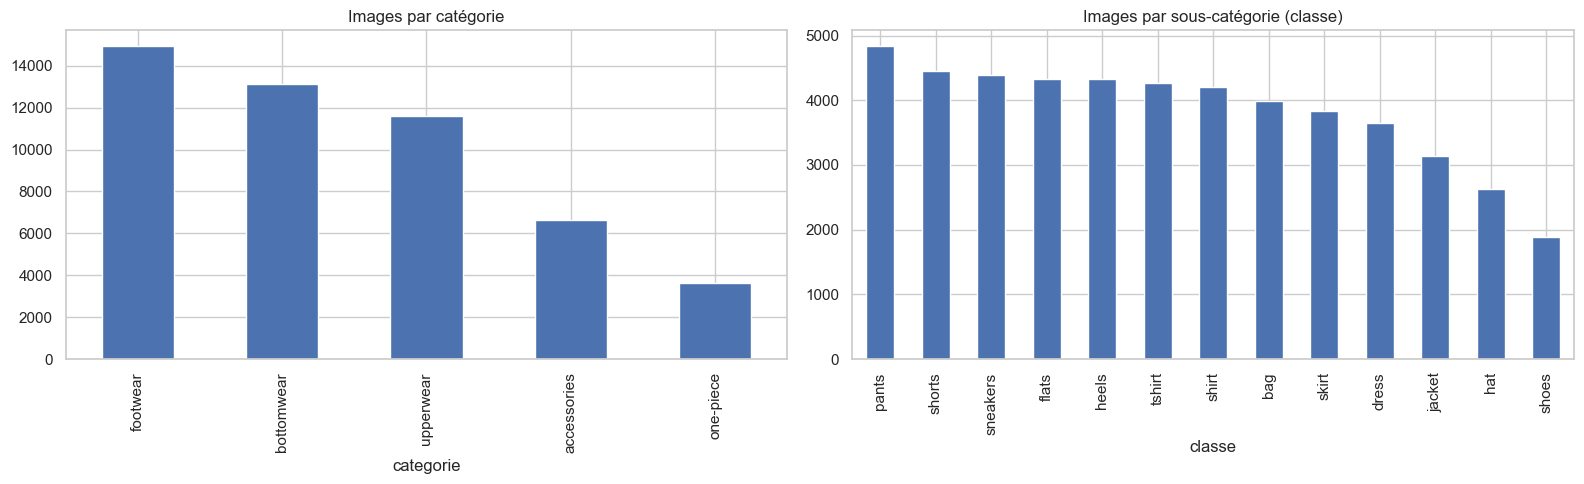

Déséquilibre : la plus grande classe a 2.6 fois plus d'images que la plus petite


In [5]:
par_cat = sdf.groupBy("categorie").count().orderBy(F.desc("count")).toPandas().set_index("categorie")["count"]
cnt = sdf.groupBy("classe").count().orderBy(F.desc("count")).toPandas().set_index("classe")["count"]

fig, ax = plt.subplots(1, 2, figsize=(16, 5))
par_cat.plot.bar(ax=ax[0], title="Images par catégorie")
cnt.plot.bar(ax=ax[1], title="Images par sous-catégorie (classe)")
plt.tight_layout(); plt.show()
print(f"Déséquilibre : la plus grande classe a {cnt.max() / cnt.min():.1f} fois plus d'images que la plus petite")

### Exemples d'images

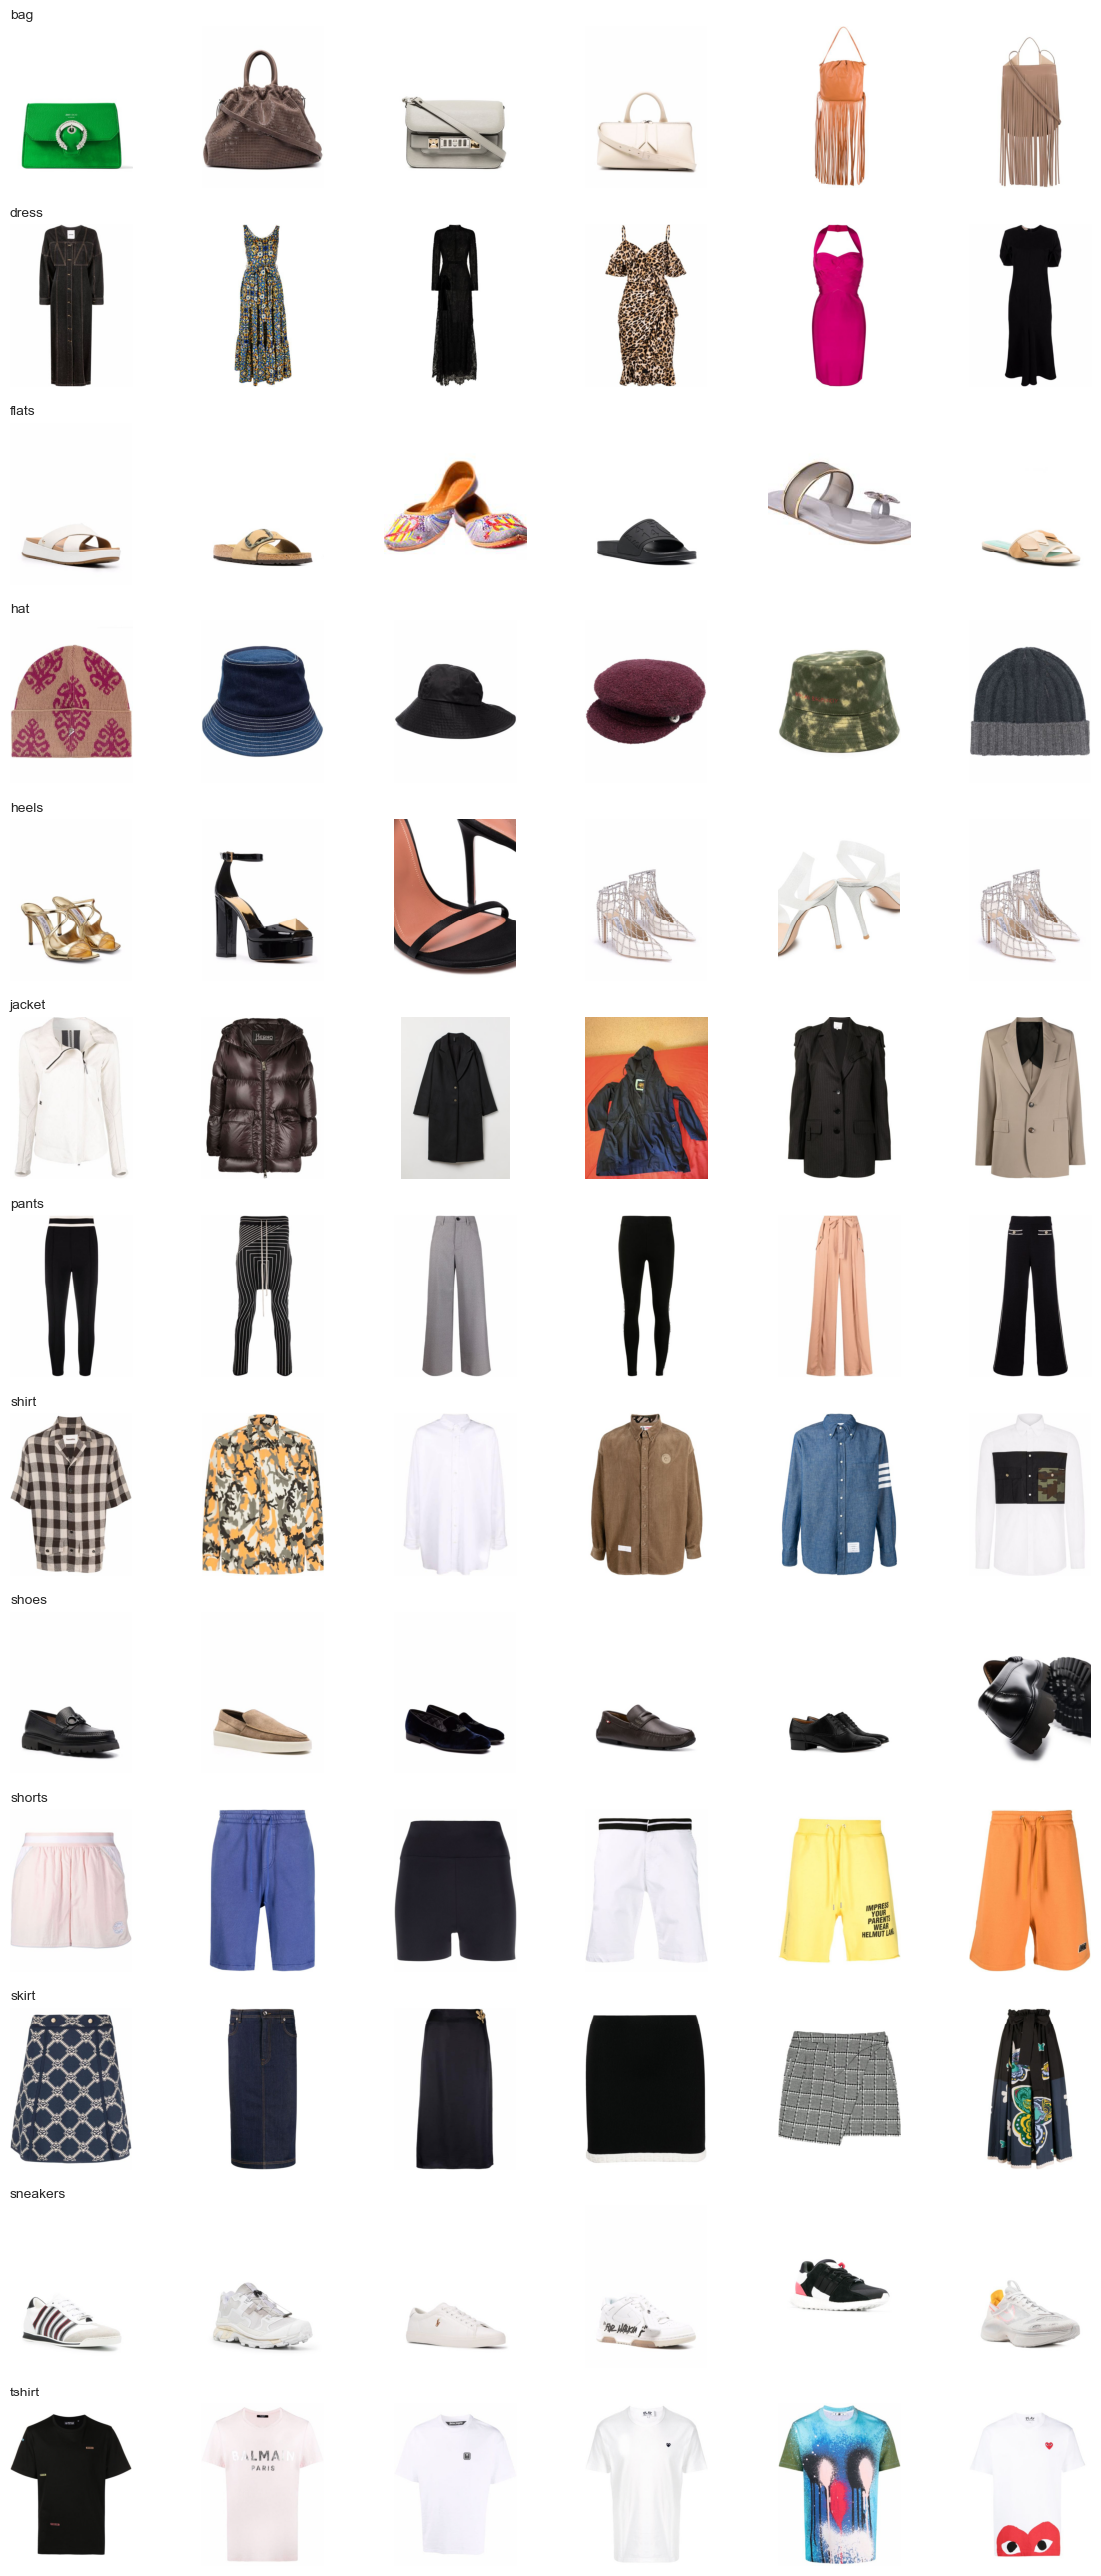

In [6]:
classes = sorted(cnt.index)
# 6 images au hasard par classe, tirées par Spark (fenêtre par classe)
w = Window.partitionBy("classe").orderBy(F.rand(SEED))
exemples = sdf.withColumn("n", F.row_number().over(w)).filter("n <= 6").select("classe", "path").toPandas()

fig, axes = plt.subplots(len(classes), 6, figsize=(12, 2 * len(classes)))
for ax in axes.flat:
    ax.axis("off")
for i, c in enumerate(classes):
    for j, path in enumerate(exemples.loc[exemples["classe"] == c, "path"]):
        axes[i, j].imshow(Image.open(path).convert("RGB"))
    axes[i, 0].set_title(c, loc="left", fontsize=10)
plt.tight_layout(); plt.show()

### Dimensions, mode couleur et taille des fichiers (toutes les images, avec Spark)

Une **pandas UDF** ouvre l'en-tête de chaque image (`Image.open` ne décode pas les pixels). Spark découpe les 50 000 chemins en partitions traitées en parallèle sur tous les cœurs, et seules 3 petites colonnes (largeur, hauteur, mode) reviennent. Les statistiques sont calculées par Spark ; pour les graphiques, un échantillon de 5 000 images suffit.

Modes couleur : {'RGB': 49933, 'L': 1}


+-------+------------------+-----------------+-------------------+------------------+
|summary|           largeur|          hauteur|              ratio|         taille_ko|
+-------+------------------+-----------------+-------------------+------------------+
|  count|             49934|            49934|              49934|             49934|
|   mean|469.20523090479435|624.8779188528858| 0.7531918177963948|137.34428011381274|
|    min|               225|              257|0.42735042735042733|      7.3525390625|
|    25%|               480|              640|  0.748829953198128|      65.251953125|
|    50%|               480|              640|               0.75|      105.30078125|
|    75%|               480|              641|               0.75|       183.2421875|
|    max|               888|              936|               2.22|     715.912109375|
+-------+------------------+-----------------+-------------------+------------------+



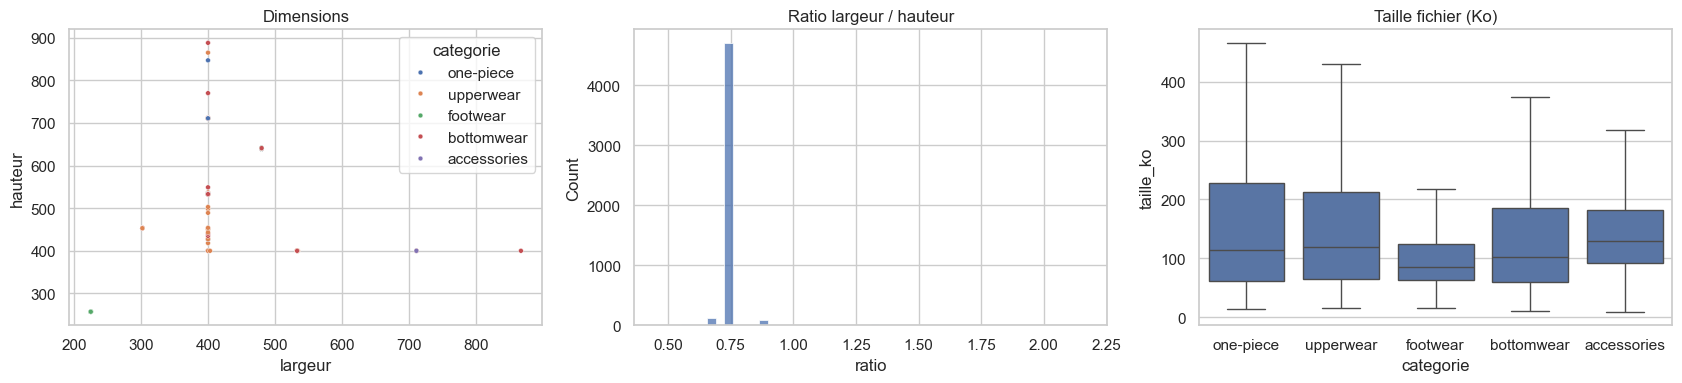

In [7]:
@F.pandas_udf("largeur int, hauteur int, mode string")
def entete(paths: pd.Series) -> pd.DataFrame:
    lignes = []
    for p in paths:
        try:
            with Image.open(p) as im:   # lit seulement l'en-tête du fichier
                lignes.append((im.width, im.height, im.mode))
        except Exception:
            lignes.append((None, None, None))   # fichier illisible : traité au prétraitement
    return pd.DataFrame(lignes, columns=["largeur", "hauteur", "mode"]).astype({"largeur": "Int32", "hauteur": "Int32"})

dims = (sdf.withColumn("e", entete("path")).select("categorie", "taille_ko", "e.*")
           .withColumn("ratio", F.col("largeur") / F.col("hauteur")).cache())

print("Modes couleur :", {r["mode"]: r["count"] for r in dims.groupBy("mode").count().collect()})
dims.select("largeur", "hauteur", "ratio", "taille_ko").summary("count", "mean", "min", "25%", "50%", "75%", "max").show()

ech = dims.sample(fraction=min(1.0, 5000 / n), seed=SEED).toPandas()
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.scatterplot(data=ech, x="largeur", y="hauteur", hue="categorie", s=12, ax=ax[0]).set_title("Dimensions")
sns.histplot(ech["ratio"], bins=50, ax=ax[1]).set_title("Ratio largeur / hauteur")
sns.boxplot(data=ech, x="categorie", y="taille_ko", ax=ax[2], showfliers=False).set_title("Taille fichier (Ko)")
plt.tight_layout(); plt.show()

**Bilan de l'EDA**
- Les classes sont déséquilibrées → on utilisera des poids de classe et on regardera le F1 par classe, pas seulement l'accuracy.
- Les images n'ont pas toutes la même taille et certaines ont un canal alpha (RGBA) ou sont en niveaux de gris → il faudra les ramener toutes au même format RGB et à la même taille.
- Certaines classes se ressemblent visuellement (shoes / sneakers / flats, shirt / t-shirt / jacket) : on s'attend à des confusions entre elles.

## [Prétraitement]

## 3. Prétraitement

1. **Images illisibles** (Spark) : on vérifie que chaque fichier peut vraiment être décodé, sinon l'entraînement planterait au milieu. Une pandas UDF décode les 50 000 images en parallèle sur tous les cœurs, puis on retire les fichiers en erreur.
2. **Passage en pandas** : il ne reste que des métadonnées (chemin, split, classe), environ 50 000 petites lignes, ce qui tient sans problème en mémoire. On arrête ensuite Spark pour laisser la RAM à TensorFlow.
3. **Encodage des étiquettes** : chaque classe reçoit un numéro.
4. **Découpage train / validation / test** : si l'archive fournit déjà un dossier test on le garde, sinon on en crée un. La validation (15 % du train) sert à arrêter l'entraînement au bon moment. Le découpage est **stratifié** (mêmes proportions de classes partout).

In [8]:
@F.pandas_udf("boolean")
def lisible(paths: pd.Series) -> pd.Series:
    def ok(p):
        try:
            with Image.open(p) as im:
                im.load()   # décode vraiment les pixels
            return True
        except Exception:
            return False
    return paths.map(ok)

sdf = sdf.withColumn("ok", lisible("path")).cache()
mauvais = sdf.filter(~F.col("ok"))
print("Images illisibles :", mauvais.count())
mauvais.select("path").show(truncate=False)

df = sdf.filter("ok").drop("ok").toPandas()   # métadonnées seulement, pas les images
spark.stop()   # libère la mémoire de la JVM pour l'entraînement TensorFlow
print(len(df), "images gardées")

Images illisibles : 0
+----+
|path|
+----+
+----+



49934 images gardées


In [9]:
classes = sorted(df["classe"].unique())
CLASS_ID = {c: i for i, c in enumerate(classes)}
df["label"] = df["classe"].map(CLASS_ID)
N_CLASSES = len(classes)

splits = set(df["split"])
if {"train", "val", "test"} <= splits:   # découpage fourni par Kaggle
    train_df, val_df, test_df = (df[df["split"] == s] for s in ("train", "val", "test"))
else:
    if {"train", "test"} <= splits:
        train_full, test_df = df[df["split"] == "train"], df[df["split"] == "test"]
    else:
        train_full, test_df = train_test_split(df, test_size=0.15, stratify=df["label"], random_state=SEED)
    train_df, val_df = train_test_split(train_full, test_size=0.15, stratify=train_full["label"], random_state=SEED)
print(f"train {len(train_df)} | validation {len(val_df)} | test {len(test_df)} | {N_CLASSES} classes")

poids = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=train_df["label"])
CLASS_WEIGHT = dict(enumerate(poids))
pd.Series(poids, index=classes).round(2)

train 40139 | validation 4784 | test 5011 | 13 classes


bag         0.97
dress       1.05
flats       0.89
hat         1.45
heels       0.89
jacket      1.23
pants       0.79
shirt       0.91
shoes       2.05
shorts      0.86
skirt       1.00
sneakers    0.88
tshirt      0.90
dtype: float64

## [Transformation]

## 4. Transformation : pipeline `tf.data`

Pour chaque image, lue à la volée :
- décodage PNG/JPG en **3 canaux RGB** (supprime l'alpha, convertit le gris) ;
- **redimensionnement** à 160 × 160 en gardant les proportions (padding) pour ne pas déformer l'article ;
- **normalisation** des pixels dans l'intervalle attendu par le réseau pré-entraîné ([-1, 1] pour MobileNetV2) ;
- **augmentation de données** (train seulement) : miroir horizontal, petite rotation, zoom, contraste. Le modèle voit des variantes différentes à chaque époque, ce qui limite le sur-apprentissage.

Le pipeline traite les images **en parallèle** (`num_parallel_calls=AUTOTUNE`), par **lots** de 64, et prépare le lot suivant pendant que le modèle calcule (`prefetch`). La mémoire utilisée ne dépend que de la taille du lot, pas de la taille du dataset.

Un lot : (64, 160, 160, 3) <dtype: 'float32'> | pixels entre -1.0 et 1.0


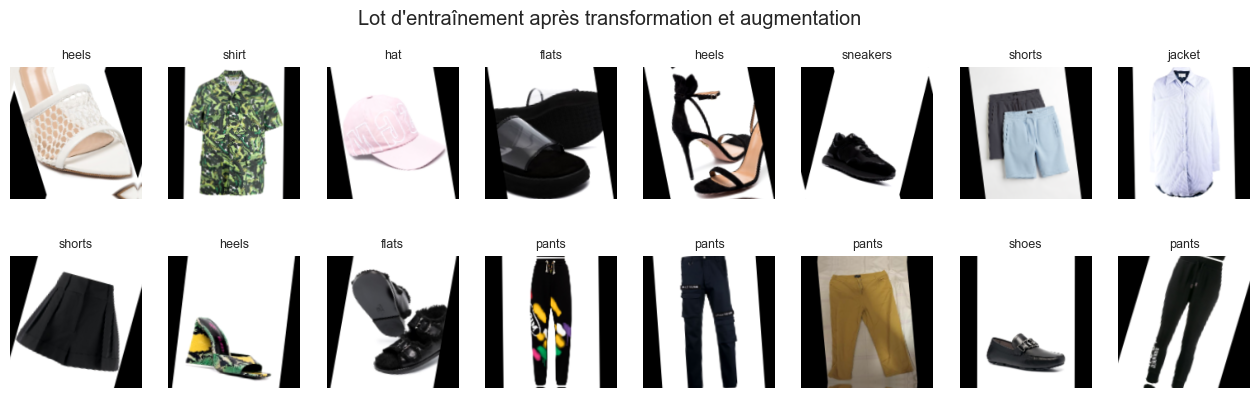

In [10]:
IMG = 160
BATCH = 64
AUTOTUNE = tf.data.AUTOTUNE

def charger(path, label):
    img = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    return tf.image.resize_with_pad(img, IMG, IMG), label   # pixels encore entre 0 et 255

augment = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.1),
])

def make_ds(d, train=False):
    ds = tf.data.Dataset.from_tensor_slices((d["path"].values, d["label"].values))
    if train:
        ds = ds.shuffle(len(d), seed=SEED)
    ds = ds.map(charger, num_parallel_calls=AUTOTUNE).batch(BATCH)
    if train:   # augmentation AVANT la normalisation : RandomContrast attend des pixels entre 0 et 255
        ds = ds.map(lambda x, y: (augment(x, training=True), y), num_parallel_calls=AUTOTUNE)
    ds = ds.map(lambda x, y: (tf.keras.applications.mobilenet_v2.preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    return ds.prefetch(AUTOTUNE)

train_ds, val_ds, test_ds = make_ds(train_df, train=True), make_ds(val_df), make_ds(test_df)

x, y = next(iter(train_ds))
print("Un lot :", x.shape, x.dtype, "| pixels entre", float(tf.reduce_min(x)), "et", float(tf.reduce_max(x)))
fig, axes = plt.subplots(2, 8, figsize=(16, 4.5))
for ax, im, lab in zip(axes.flat, x[:16], y[:16]):
    ax.imshow((im.numpy() + 1) / 2); ax.set_title(classes[int(lab)], fontsize=9); ax.axis("off")
plt.suptitle("Lot d'entraînement après transformation et augmentation"); plt.show()

## [ML]

## 5. Modélisation (ML) : transfer learning

Entraîner un réseau de neurones convolutif depuis zéro demanderait beaucoup de temps de calcul. On utilise **MobileNetV2 pré-entraîné sur ImageNet** (1,4 million d'images) : ses couches savent déjà reconnaître bords, textures et formes. On le **gèle** et on n'entraîne qu'une petite tête de classification par-dessus.

1. **Phase 1** : base gelée, on entraîne la tête (rapide).
2. **Phase 2 (fine-tuning)** : on dégèle les dernières couches de MobileNetV2 et on continue avec un taux d'apprentissage 10 fois plus petit, pour les adapter aux vêtements.

`EarlyStopping` arrête l'entraînement quand la perte de validation ne s'améliore plus et garde les meilleurs poids.

In [11]:
EPOCHS_TETE, EPOCHS_FINE = 3, 2   # réduit (au lieu de 8, 5) pour tenir en ~1 h sur CPU

base = tf.keras.applications.MobileNetV2(input_shape=(IMG, IMG, 3), include_top=False, weights="imagenet")
base.trainable = False

model = tf.keras.Sequential([
    tf.keras.Input((IMG, IMG, 3)),
    base,
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.3),
    tf.keras.layers.Dense(N_CLASSES, activation="softmax"),
])
model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

stop = tf.keras.callbacks.EarlyStopping(monitor="val_loss", patience=2, restore_best_weights=True)
h1 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_TETE, class_weight=CLASS_WEIGHT, callbacks=[stop])

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 13)             │        16,653 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,274,637 (8.68 MB)

 Trainable params: 16,653 (65.05 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

Epoch 1/3


... (2 outputs left out)

Epoch 2/3


628/628 ━━━━━━━━━━━━━━━━━━━━ 301s 478ms/step - accuracy: 0.8663 - loss: 0.3973 - val_accuracy: 0.8965 - val_loss: 0.3016


Epoch 3/3


628/628 ━━━━━━━━━━━━━━━━━━━━ 300s 476ms/step - accuracy: 0.8775 - loss: 0.3608 - val_accuracy: 0.8955 - val_loss: 0.2983


In [12]:
base.trainable = True
for couche in base.layers[:-30]:   # on ne dégèle que les 30 dernières couches
    couche.trainable = False
model.compile(optimizer=tf.keras.optimizers.Adam(1e-4), loss="sparse_categorical_crossentropy", metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS_FINE, class_weight=CLASS_WEIGHT, callbacks=[stop])

Epoch 1/2


628/628 ━━━━━━━━━━━━━━━━━━━━ 373s 584ms/step - accuracy: 0.8945 - loss: 0.3216 - val_accuracy: 0.9229 - val_loss: 0.2952


Epoch 2/2


628/628 ━━━━━━━━━━━━━━━━━━━━ 376s 598ms/step - accuracy: 0.9404 - loss: 0.1784 - val_accuracy: 0.9352 - val_loss: 0.2260


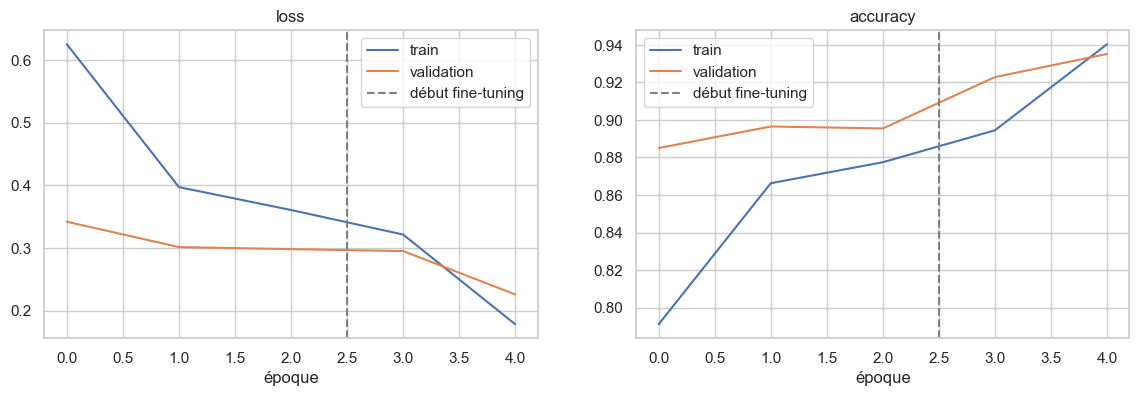

In [13]:
hist = {k: h1.history[k] + h2.history[k] for k in h1.history}
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
for k, a in [("loss", ax[0]), ("accuracy", ax[1])]:
    a.plot(hist[k], label="train"); a.plot(hist["val_" + k], label="validation")
    a.axvline(len(h1.history["loss"]) - 0.5, color="grey", ls="--", label="début fine-tuning")
    a.set_title(k); a.set_xlabel("époque"); a.legend()
plt.show()

## [Éval]

## 6. Évaluation sur le jeu de test

Le jeu de test n'a jamais été vu pendant l'entraînement.
- **Accuracy** : pourcentage d'images bien classées.
- **Précision / rappel / F1 par classe** : indispensables car les classes sont déséquilibrées.
- **F1 macro** : moyenne des F1 de chaque classe, chaque classe compte autant.
- **Matrice de confusion** : montre quelles classes sont confondues entre elles.

In [14]:
proba = model.predict(test_ds)
y_pred = proba.argmax(1)
y_true = test_df["label"].values
print(f"Accuracy test : {accuracy_score(y_true, y_pred):.3f} | F1 macro : {f1_score(y_true, y_pred, average='macro'):.3f}\n")
print(classification_report(y_true, y_pred, target_names=classes, digits=3))

79/79 ━━━━━━━━━━━━━━━━━━━━ 33s 396ms/step


Accuracy test : 0.939 | F1 macro : 0.936

              precision    recall  f1-score   support

         bag      0.945     0.990     0.967       399
       dress      0.956     0.967     0.961       359
       flats      0.961     0.850     0.902       434
         hat      0.973     0.969     0.971       262
       heels      0.919     0.998     0.957       434
      jacket      0.967     0.798     0.874       331
       pants      0.996     0.947     0.971       476
       shirt      0.851     0.971     0.907       416
       shoes      0.858     0.926     0.891       189
      shorts      0.975     0.934     0.954       453
       skirt      0.874     0.938     0.905       384
    sneakers      0.962     0.920     0.941       440
      tshirt      0.959     0.977     0.968       434

    accuracy                          0.939      5011
   macro avg      0.938     0.937     0.936      5011
weighted avg      0.941     0.939     0.938      5011



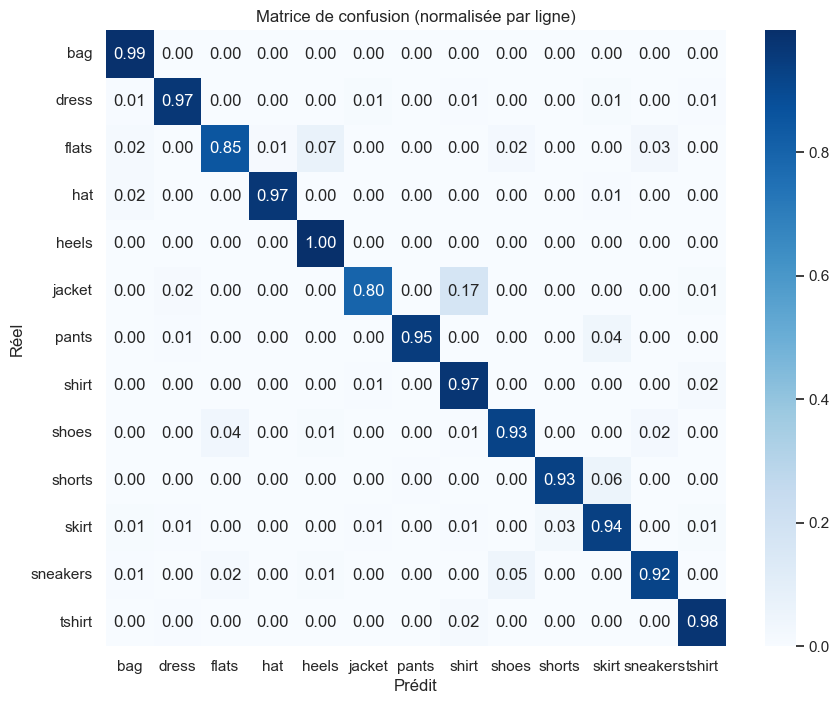

In [15]:
cm = confusion_matrix(y_true, y_pred, normalize="true")
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Prédit"); plt.ylabel("Réel"); plt.title("Matrice de confusion (normalisée par ligne)")
plt.show()

### Précision au niveau des 5 grandes catégories
Une erreur *sneakers → shoes* est moins grave qu'une erreur *sneakers → dress* : on regarde aussi si la grande catégorie est juste.

In [16]:
classe_vers_cat = df.drop_duplicates("classe").set_index("classe")["categorie"]
cat_true = classe_vers_cat[[classes[i] for i in y_true]].values
cat_pred = classe_vers_cat[[classes[i] for i in y_pred]].values
print(f"Accuracy sur la catégorie : {accuracy_score(cat_true, cat_pred):.3f}")

Accuracy sur la catégorie : 0.986


### Exemples d'erreurs

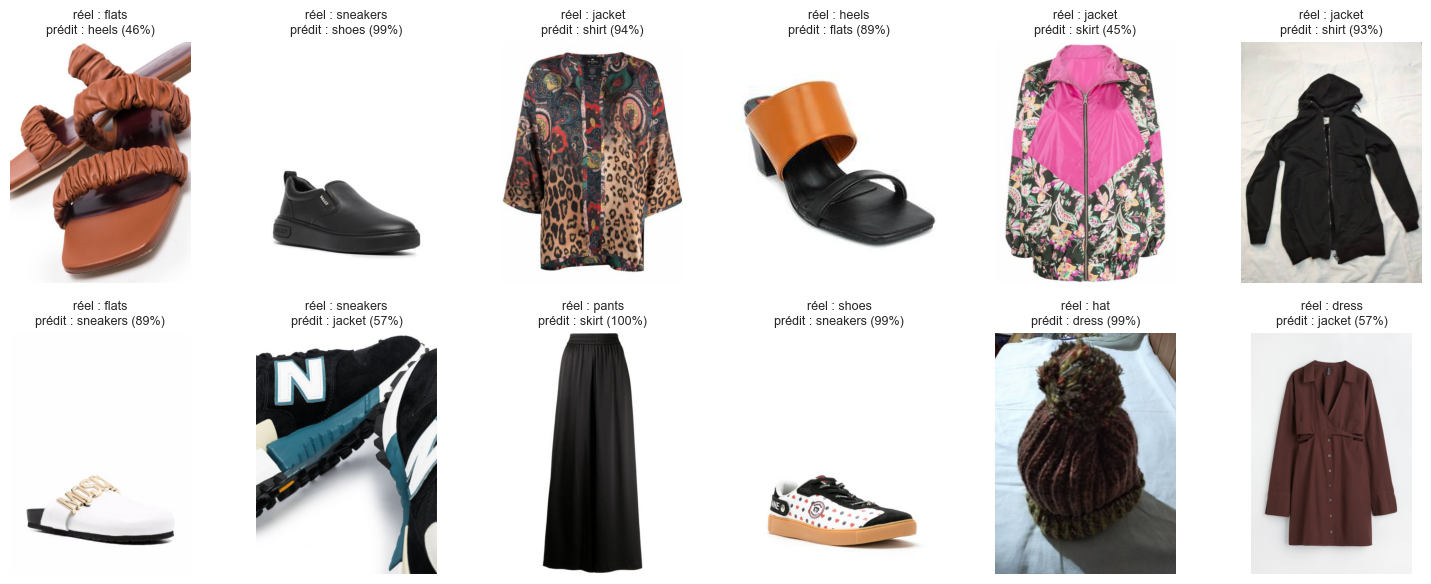

In [17]:
erreurs = np.where(y_pred != y_true)[0]
fig, axes = plt.subplots(2, 6, figsize=(15, 6))
for ax, i in zip(axes.flat, np.random.choice(erreurs, min(12, len(erreurs)), replace=False)):
    ax.imshow(Image.open(test_df["path"].iloc[i]).convert("RGB")); ax.axis("off")
    ax.set_title(f"réel : {classes[y_true[i]]}\nprédit : {classes[y_pred[i]]} ({proba[i].max():.0%})", fontsize=9)
plt.tight_layout(); plt.show()

## [Déploiement]

In [18]:
model.save("outfit_mobilenetv2.keras")

## [Conclusion]

## 7. Conclusion

- **EDA (Spark)** : ~49 000 images, 13 classes déséquilibrées, tailles et formats couleur variables, mesurés sur toutes les images en parallèle.
- **Prétraitement (Spark puis pandas)** : vérification de tous les fichiers en parallèle, étiquettes numériques, découpage stratifié, poids de classe.
- **Transformation** : pipeline `tf.data` en flux (RGB, redimensionnement avec padding, normalisation, augmentation), sans jamais charger les 7 Go en mémoire.
- **ML** : transfer learning MobileNetV2 + fine-tuning, bien plus efficace qu'un CNN entraîné depuis zéro avec ce volume et ce temps de calcul.
- **Évaluation** : les erreurs se concentrent entre classes visuellement proches d'une même catégorie (chaussures entre elles, hauts entre eux), ce que confirme la bonne accuracy au niveau catégorie.
- **Résultats sur le test** (3 + 2 époques) : accuracy **0,939**, F1 macro **0,936**, accuracy au niveau des 5 catégories **0,986**. Classes les plus difficiles : *jacket* (rappel 0,80) et *flats* (rappel 0,85).

Pistes : images plus grandes (224 px), modèle plus gros (EfficientNet), entraînement sur GPU ou distribué (`tf.distribute`) pour passer à l'échelle.